# Every figure, redrawn without training

Run this notebook to redraw every figure in `figures/` without training anything.

* The experiment figures (H1, H2, sustainability) only read the numbers that the experiment notebooks saved in
  `results/`.
* The dataset and KryptoNet-40 figures are computed directly from the data files and the pretrained weights; nothing
  is trained.

It takes a few minutes, mostly for the correlations of every triple of features.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from include.figures import use_paper_style, savefig
from include.saved import load_h1, load_h1_features, load_h2
from include.tracking import load_json
from include import plots_data, plots_kryptonet, plots_h1, plots_h2, plots_sustainability

use_paper_style()
MODELS = ["LogReg (d=1)", "LogReg (d=2)", "MLP (raw x)", "MLP (sign x)"]  # same order as in H1_learnability


def redraw(fig, name):
    savefig(fig, name)
    plt.show()
    plt.close(fig)

## Datasets (from the data files)

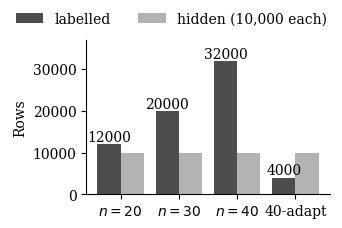

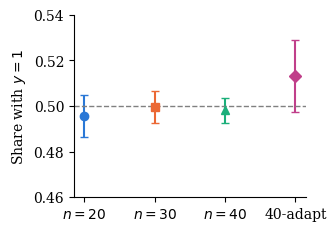

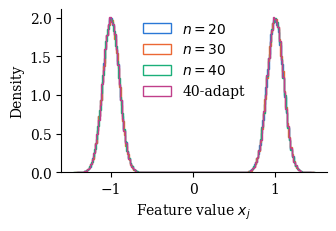

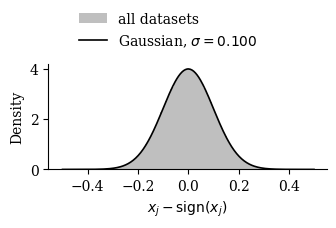

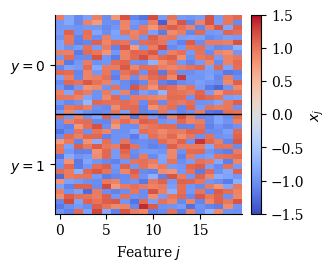

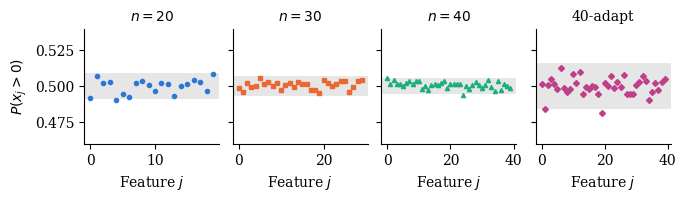

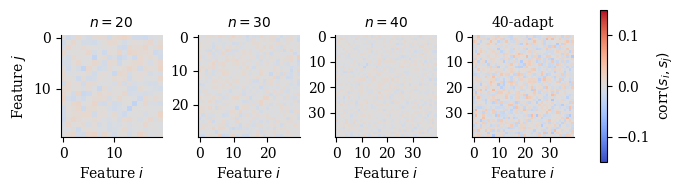

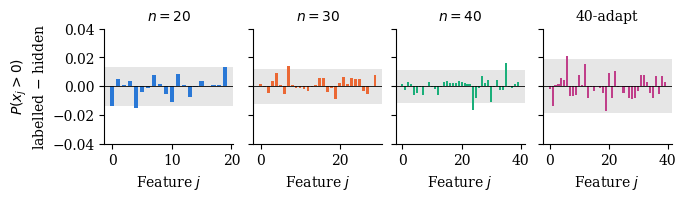

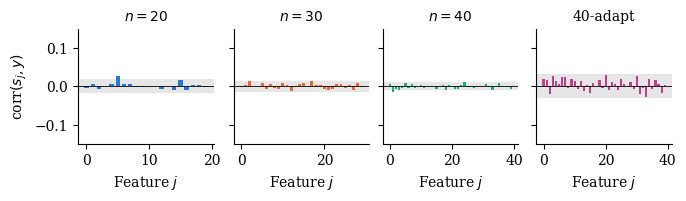

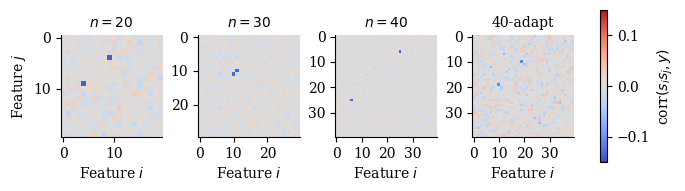

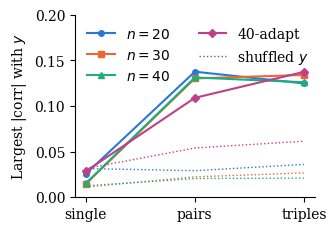

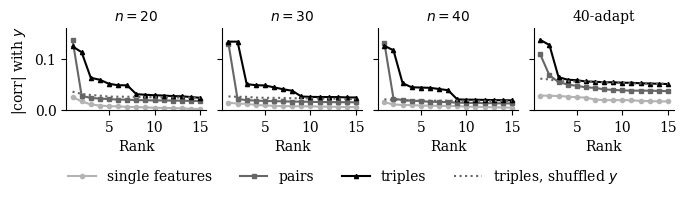

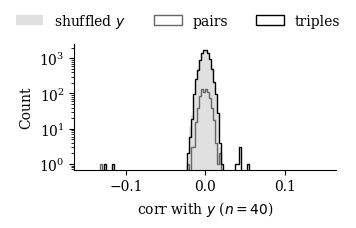

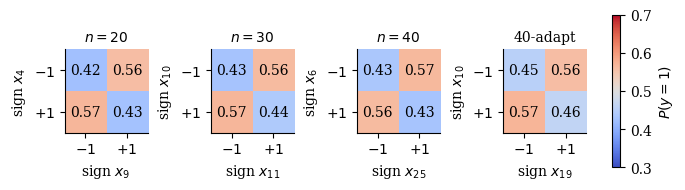

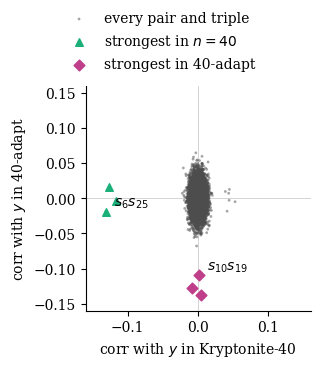

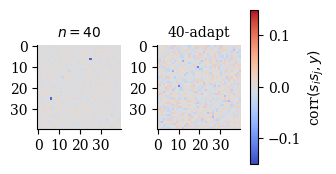

In [2]:
DATA_FIGURES = {
    "data_sizes": plots_data.plot_sizes,
    "data_class_balance": plots_data.plot_class_balance,
    "data_value_hist": plots_data.plot_value_hist,
    "data_noise_hist": plots_data.plot_noise_hist,
    "data_rows": plots_data.plot_rows,
    "data_positive_share": plots_data.plot_positive_share,
    "data_feature_corr": plots_data.plot_feature_corr,
    "data_train_vs_hidden": plots_data.plot_train_vs_hidden,
    "data_single_corr": plots_data.plot_single_corr,
    "data_pair_corr": plots_data.plot_pair_corr,
    "data_corr_by_order": plots_data.plot_corr_by_order,
    "data_corr_ranked": plots_data.plot_corr_ranked,
    "data_corr_hist": plots_data.plot_corr_hist,
    "data_top_pair_quadrants": plots_data.plot_top_pair_quadrants,
    "data_40_vs_adapt": plots_data.plot_40_vs_adapt,
    "data_40_vs_adapt_pairs": plots_data.plot_40_vs_adapt_pairs,
}
for name, plot in DATA_FIGURES.items():
    redraw(plot(), name)

## KryptoNet-40 (from the pretrained weights)

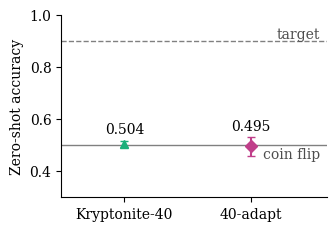

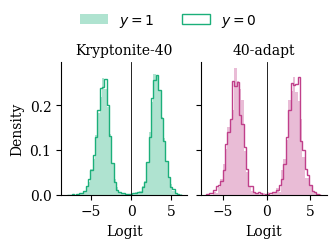

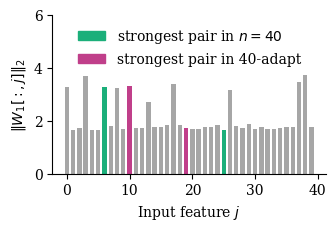

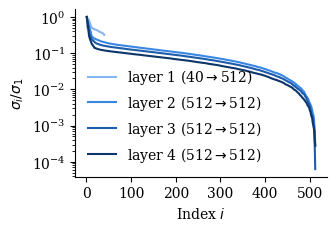

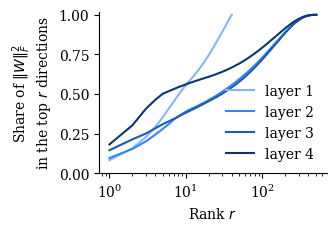

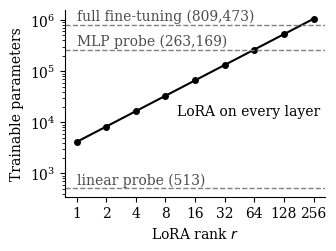

In [3]:
KRYPTONET_FIGURES = {
    "kn_zero_shot": plots_kryptonet.plot_zero_shot,
    "kn_logits": plots_kryptonet.plot_logits,
    "kn_input_weights": plots_kryptonet.plot_input_weights,
    "kn_weight_spectra": plots_kryptonet.plot_weight_spectra,
    "kn_weight_energy": plots_kryptonet.plot_weight_energy,
    "kn_lora_params": plots_kryptonet.plot_lora_params,
}
for name, plot in KRYPTONET_FIGURES.items():
    redraw(plot(), name)

## H1 (the report uses `H1_summary`; from `results/H1_learnability.json` and `results/H1_features.json`)

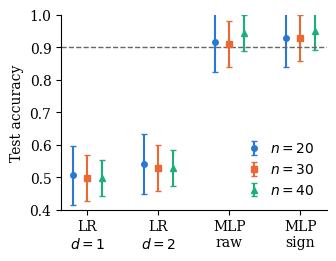

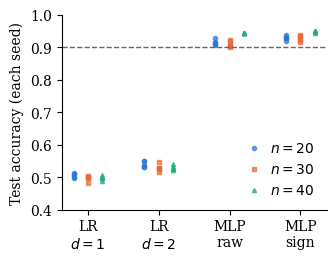

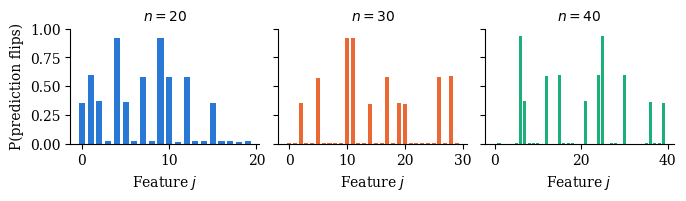

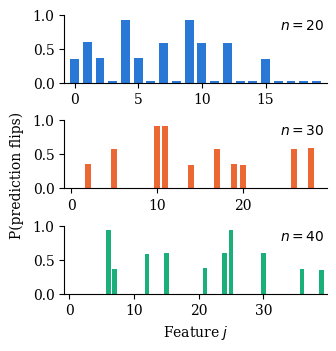

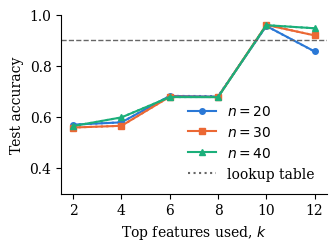

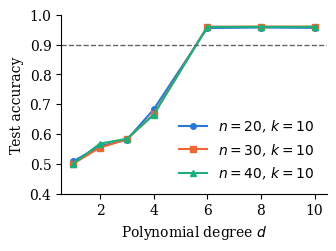

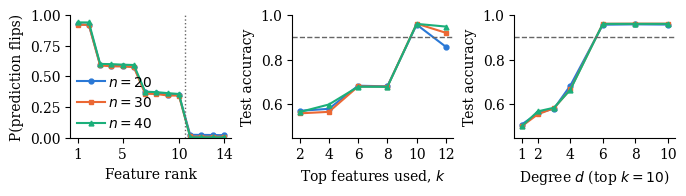

In [4]:
summary, results = load_h1()
redraw(plots_h1.plot_h1_models(summary, MODELS), "H1_models")
redraw(plots_h1.plot_h1_seeds(results, MODELS), "H1_seeds")

res, feature_summary = load_h1_features()
redraw(plots_h1.plot_influence({n: np.mean(res[n]["influence"], axis=0) for n in res}), "H1_influence")
redraw(plots_h1.plot_influence_column({n: np.mean(res[n]["influence"], axis=0) for n in res}), "H1_influence_col")
redraw(plots_h1.plot_topk(res), "H1_topk")
k_for = {n: int(feature_summary[n]["poly"]["choice"].split(",")[0]) for n in res}
redraw(plots_h1.plot_poly_degree(res, k_for), "H1_poly_degree")
redraw(plots_h1.plot_h1_summary(res, k_for), "H1_summary")  # the report's H1 figure

## H2 (from `results/H2_more_data.json`)

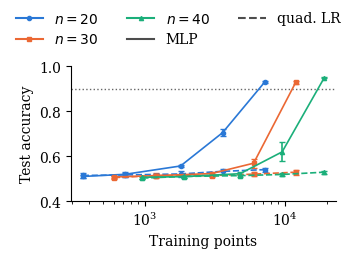

In [5]:
curves, n_train = load_h2()
fractions = sorted(next(iter(curves.values()))["MLP"])
redraw(plots_h2.plot_learning_curves(curves, fractions, n_train), "H2_learning_curves")

## Sustainability (from `results/runtime_log.json`)

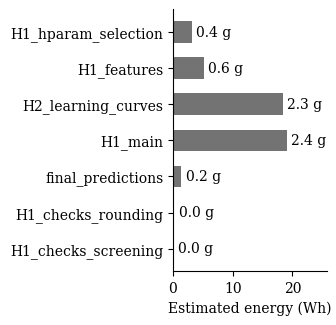

In [6]:
redraw(plots_sustainability.plot_energy(load_json("runtime_log.json")), "sustainability_energy")